# Classification and Evaluation in NLP

**Text classification** is a common Natural Language Processing (NLP) task where a model assigns a predefined category or label to a piece of text.

Examples include:
- Spam detection
- Sentiment analysis
- News categorization

In this lab, we will learn how to build and evaluate a text classification model.

## Case Study: Sentiment Analysis

Sentiment analysis, also known as opinion mining, its goal is to understand the information present in the text and categorize it as positive, negative, or neutral.

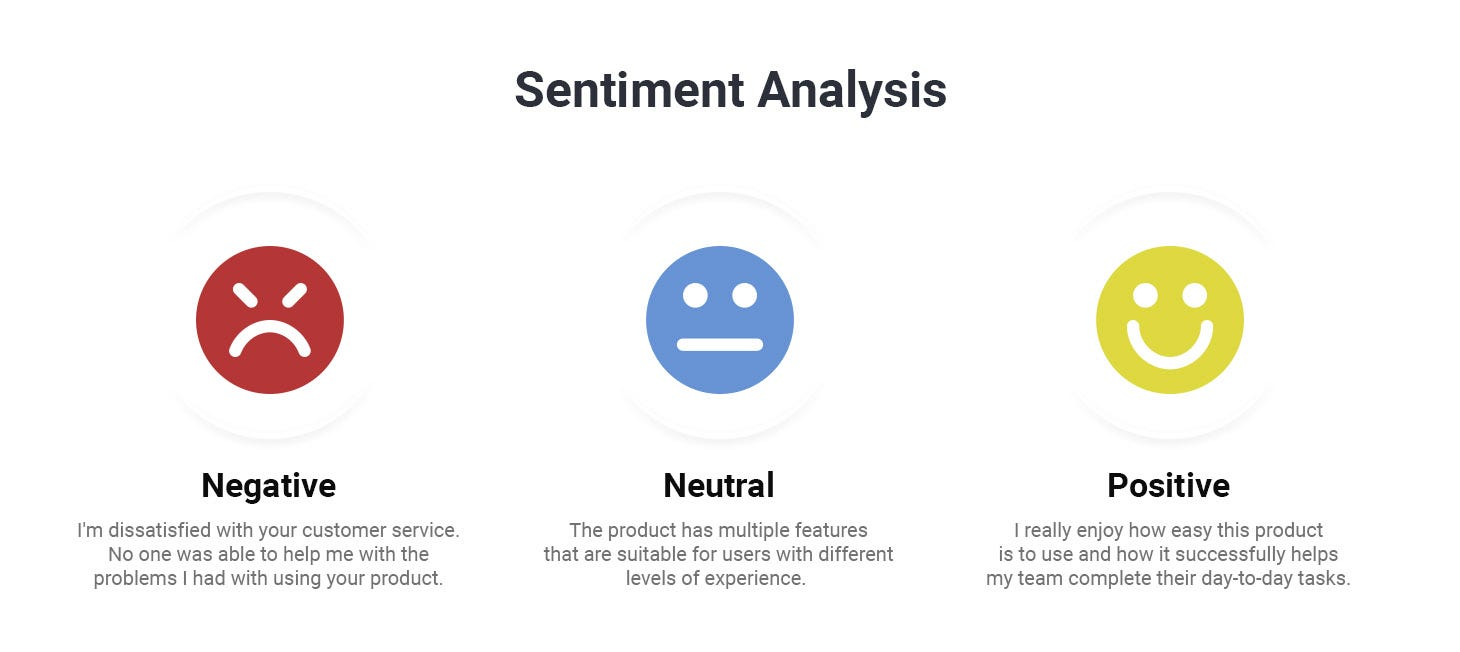

# Disneyland Reviews Dataset
In this lab we'll look into Disneyland Reviews dataset.  
*Link: https://www.kaggle.com/datasets/arushchillar/disneyland-reviews*

The dataset includes 42,000 reviews of 3 Disneyland branches - Paris, California and Hong Kong, posted by visitors on Trip Advisor.

Column Description:

- Review_ID: unique id given to each review
- Rating: ranging from 1 (unsatisfied) to 5 (satisfied)
- Year_Month: when the reviewer visited the theme park
- Reviewer_Location: country of origin of visitor
- Review_Text: comments made by visitor
- Disneyland_Branch: location of Disneyland Park

In [1]:
# Load the dataset
import pandas as pd

data = pd.read_csv('DisneylandReviews.csv', encoding='latin-1')
data

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong
...,...,...,...,...,...,...
42651,1765031,5,missing,United Kingdom,i went to disneyland paris in july 03 and thou...,Disneyland_Paris
42652,1659553,5,missing,Canada,2 adults and 1 child of 11 visited Disneyland ...,Disneyland_Paris
42653,1645894,5,missing,South Africa,My eleven year old daughter and myself went to...,Disneyland_Paris
42654,1618637,4,missing,United States,"This hotel, part of the Disneyland Paris compl...",Disneyland_Paris


In [2]:
#Check for missing values
data.isna().sum()

Review_ID            0
Rating               0
Year_Month           0
Reviewer_Location    0
Review_Text          0
Branch               0
dtype: int64

In [3]:
# Drop rows with missing values in the relevant columns
data = data.dropna(subset=['Review_Text', 'Rating'])

In [4]:
# Map star ratings to sentiments
data['Sentiment'] = data['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))
data.head()

,Review_ID,Rating,Year_Month,Reviewer_Location,Review_Text,Branch,Sentiment
0,670772142,4,2019-4,Australia,If you've ever been to Disneyland anywhere you...,Disneyland_HongKong,positive
1,670682799,4,2019-5,Philippines,Its been a while since d last time we visit HK...,Disneyland_HongKong,positive
2,670623270,4,2019-4,United Arab Emirates,Thanks God it wasn t too hot or too humid wh...,Disneyland_HongKong,positive
3,670607911,4,2019-4,Australia,HK Disneyland is a great compact park. Unfortu...,Disneyland_HongKong,positive
4,670607296,4,2019-4,United Kingdom,"the location is not in the city, took around 1...",Disneyland_HongKong,positive


In [5]:
# Import necessary libraries
import re
import nltk

def preprocess_text(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # 3. Tokenize the text
    words = text.split()

    return ' '.join(words)

# Apply preprocessing to the review text
data['Review_Text'] = data['Review_Text'].apply(preprocess_text)

# Display cleaned reviews
data[['Review_Text', 'Sentiment']].head()

,Review_Text,Sentiment
0,if youve ever been to disneyland anywhere youl...,positive
1,its been a while since d last time we visit hk...,positive
2,thanks god it wasn t too hot or too humid when...,positive
3,hk disneyland is a great compact park unfortun...,positive
4,the location is not in the city took around ho...,positive


In [6]:
# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Split the dataset into training and testing sets
train_data, test_data, train_labels, test_labels = train_test_split(data['Review_Text'], data['Sentiment'], test_size=0.2, random_state=42)


# TF-IDF Vectorization
tfidf_vectorizer = TfidfVectorizer(max_features=1000)  # You can adjust max_features based on your dataset size - limit vocabulary to the 1000 most informative tokens
train_vectors = tfidf_vectorizer.fit_transform(train_data)
test_vectors = tfidf_vectorizer.transform(test_data)

In [7]:
print(f"train_data size: {train_data.shape}")
print(f"test_data size: {test_data.shape}")

train_data size: (34124,)
test_data size: (8532,)


In [8]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Train the Support Vector Machine (SVM) classifier
svm_classifier = SVC(kernel='linear')
svm_classifier.fit(train_vectors, train_labels)

# Predictions on the test set
predictions = svm_classifier.predict(test_vectors)

# Evaluate the model
accuracy = accuracy_score(test_labels, predictions)
print(f"Accuracy: {accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(test_labels, predictions))


Accuracy: 0.84
Classification Report:


              precision    recall  f1-score   support

    negative       0.64      0.54      0.59       720
     neutral       0.48      0.18      0.26      1035
    positive       0.88      0.97      0.92      6777

    accuracy                           0.84      8532
   macro avg       0.66      0.56      0.59      8532
weighted avg       0.81      0.84      0.81      8532



# Use Case:  Amazon reviews of unlocked phone analysis

The objective of this use case is to conduct sentiment analysis on Amazon reviews of unlocked phones, categorizing reviews into three classes: positive, negative, and neutral. The goal is to gain a comprehensive understanding of customer opinions and sentiments regarding various unlocked phone models.

- Dataset link: https://www.kaggle.com/datasets/PromptCloudHQ/amazon-reviews-unlocked-mobile-phones

Task1: Load the data and do 5 different preprocessing steps on it

Task2: Use a proper train and test split

Task3: Do Feature Extraction Using TF-IDF

Task4: Train a Naive Bayes Classifier

Task5: Evaluate the model on the Test Set

Task6: Print the Confusion Matrix

## Task1: Load the data and do 5 different preprocessing steps on it

The CSV file `Amazon_Unlocked_Mobile.csv` is placed in the same folder as this notebook.

### Load the data

In [9]:
import re
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

amazon = pd.read_csv('Amazon_Unlocked_Mobile.csv')

print('Shape of the dataset:', amazon.shape)
amazon.head()

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\kemo7\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\kemo7\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\kemo7\AppData\Roaming\nltk_data...


[nltk_data]   Package wordnet is already up-to-date!


Shape of the dataset: (413840, 6)


,Product Name,Brand Name,Price,Rating,Reviews,Review Votes
0,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,I feel so LUCKY to have found this used (phone...,1.0
1,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,"nice phone, nice up grade from my pantach revu...",0.0
2,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,5,Very pleased,0.0
3,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,It works good but it goes slow sometimes but i...,0.0
4,"""CLEAR CLEAN ESN"" Sprint EPIC 4G Galaxy SPH-D7...",Samsung,199.99,4,Great phone to replace my lost phone. The only...,0.0


In [10]:
# Check for missing values
amazon.isna().sum()

Product Name        0
Brand Name      65171
Price            5933
Rating              0
Reviews            70
Review Votes    12296
dtype: int64

In [11]:
# Only the review text and the rating are needed, so rows without a review are dropped
amazon = amazon.dropna(subset=['Reviews', 'Rating']).reset_index(drop=True)
print('Shape after removing missing reviews:', amazon.shape)

# Distribution of the star ratings
amazon['Rating'].value_counts().sort_index()

Shape after removing missing reviews: (413770, 6)


Rating
1     72335
2     24724
3     31763
4     61373
5    223575
Name: count, dtype: int64

The reviews are categorized into three classes using the star rating, the same way as in the Disneyland example:

- Rating **4 or 5** → `positive`
- Rating **3** → `neutral`
- Rating **1 or 2** → `negative`

In [12]:
# Map star ratings to sentiments
amazon['Sentiment'] = amazon['Rating'].apply(lambda rating: 'positive' if rating > 3 else ('negative' if rating < 3 else 'neutral'))

print(amazon['Sentiment'].value_counts())
amazon[['Reviews', 'Rating', 'Sentiment']].head()

Sentiment
positive    284948
negative     97059
neutral      31763
Name: count, dtype: int64


,Reviews,Rating,Sentiment
0,I feel so LUCKY to have found this used (phone...,5,positive
1,"nice phone, nice up grade from my pantach revu...",4,positive
2,Very pleased,5,positive
3,It works good but it goes slow sometimes but i...,4,positive
4,Great phone to replace my lost phone. The only...,4,positive


### The 5 preprocessing steps

1. **Lower casing** — so that `Good`, `GOOD` and `good` are treated as the same word.
2. **Removing URLs, numbers, punctuation and special characters** with regular expressions.
3. **Tokenization** — splitting the review into words.
4. **Stop words removal** — removing very common words such as `the`, `is` and `a`. The negation words `no`, `not` and `nor` are **kept**, because in sentiment analysis "not good" has the opposite meaning of "good".
5. **Lemmatization** — reducing every word to its dictionary form (`phones` → `phone`).

In [13]:
from functools import lru_cache

# the negation words are kept because they change the sentiment of a review
stop_words = set(stopwords.words('english')) - {'no', 'not', 'nor'}

lemmatizer = WordNetLemmatizer()
lemmatize = lru_cache(maxsize=None)(lemmatizer.lemmatize)   # remember words that were already lemmatized

def preprocess_review(text):

    # 1. Convert text to lowercase
    text = text.lower()

    # 2. Remove URLs, numbers, punctuation and special characters
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)

    # 3. Tokenize the text
    words = word_tokenize(text)

    # 4. Remove stop words
    words = [word for word in words if word not in stop_words]

    # 5. Lemmatization
    words = [lemmatize(word) for word in words]

    return ' '.join(words)

example = "I LOVED these phones!!! They're not expensive & the batteries lasted 2 days... see http://amazon.com"
print('Before:', example)
print('After :', preprocess_review(example))

Before: I LOVED these phones!!! They're not expensive & the batteries lasted 2 days... see http://amazon.com


After : loved phone not expensive battery lasted day see


In [14]:
# Apply preprocessing to the review text
amazon['Clean_Reviews'] = amazon['Reviews'].astype(str).apply(preprocess_review)

# Some reviews become empty after cleaning (for example reviews with only emojis or numbers)
amazon = amazon[amazon['Clean_Reviews'] != ''].reset_index(drop=True)
print('Number of reviews after preprocessing:', len(amazon))

# Display cleaned reviews
amazon[['Reviews', 'Clean_Reviews', 'Sentiment']].head(10)

Number of reviews after preprocessing: 412719


,Reviews,Clean_Reviews,Sentiment
0,I feel so LUCKY to have found this used (phone...,feel lucky found used phone u not used hard ph...,positive
1,"nice phone, nice up grade from my pantach revu...",nice phone nice grade pantach revue clean set ...,positive
2,Very pleased,pleased,positive
3,It works good but it goes slow sometimes but i...,work good go slow sometimes good phone love,positive
4,Great phone to replace my lost phone. The only...,great phone replace lost phone thing volume bu...,positive
5,I already had a phone with problems... I know ...,already phone problem know stated used dang no...,negative
6,The charging port was loose. I got that solder...,charging port loose got soldered needed new ba...,negative
7,"Phone looks good but wouldn't stay charged, ha...",phone look good stay charged buy new battery s...,negative
8,I originally was using the Samsung S2 Galaxy f...,originally using samsung galaxy sprint wanted ...,positive
9,It's battery life is great. It's very responsi...,battery life great responsive touch issue some...,neutral


## Task2: Use a proper train and test split

The data is divided into **80% training** and **20% testing**. `stratify` keeps the same percentage of positive, negative and neutral reviews in both sets, which is important here because the classes are not balanced.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    amazon['Clean_Reviews'], amazon['Sentiment'],
    test_size=0.2, random_state=42, stratify=amazon['Sentiment'])

print(f"X_train size: {X_train.shape}")
print(f"X_test size : {X_test.shape}")
print()
print('Class distribution in the training set:')
print(y_train.value_counts(normalize=True).round(3))
print()
print('Class distribution in the testing set:')
print(y_test.value_counts(normalize=True).round(3))

X_train size: (330175,)
X_test size : (82544,)

Class distribution in the training set:
Sentiment
positive    0.688
negative    0.235
neutral     0.077
Name: proportion, dtype: float64

Class distribution in the testing set:
Sentiment
positive    0.688
negative    0.235
neutral     0.077
Name: proportion, dtype: float64


## Task3: Do Feature Extraction Using TF-IDF

The vectorizer is **fitted on the training set only** and then used to transform the test set, so no information from the test set is used during training.

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF Vectorization - limit the vocabulary to the 5000 most frequent tokens
amazon_tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = amazon_tfidf.fit_transform(X_train)
X_test_tfidf = amazon_tfidf.transform(X_test)

print('Training TF-IDF shape:', X_train_tfidf.shape)
print('Testing TF-IDF shape :', X_test_tfidf.shape)
print('Example features     :', list(amazon_tfidf.get_feature_names_out()[1000:1015]))

Training TF-IDF shape: (330175, 5000)
Testing TF-IDF shape : (82544, 5000)
Example features     : ['cutting', 'cuz', 'cyanogen', 'cyanogenmod', 'cycle', 'cycling', 'da', 'dad', 'daily', 'damage', 'damaged', 'damn', 'dangerous', 'dare', 'dark']


## Task4: Train a Naive Bayes Classifier

In [17]:
from sklearn.naive_bayes import MultinomialNB

# Multinomial Naive Bayes works well with word counts and TF-IDF features
nb_classifier = MultinomialNB()
nb_classifier.fit(X_train_tfidf, y_train)

print('Classes:', nb_classifier.classes_)

Classes: ['negative' 'neutral' 'positive']


## Task5: Evaluate the model on the Test Set

In [18]:
from sklearn.metrics import accuracy_score, classification_report

# Predictions on the test set
nb_predictions = nb_classifier.predict(X_test_tfidf)

# Evaluate the model
nb_accuracy = accuracy_score(y_test, nb_predictions)
print(f"Accuracy: {nb_accuracy:.2f}")

# Display classification report
print("Classification Report:")
print(classification_report(y_test, nb_predictions))

Accuracy: 0.84
Classification Report:


              precision    recall  f1-score   support

    negative       0.80      0.73      0.76     19402
     neutral       0.39      0.05      0.08      6347
    positive       0.86      0.97      0.91     56795

    accuracy                           0.84     82544
   macro avg       0.68      0.58      0.59     82544
weighted avg       0.81      0.84      0.81     82544



In [19]:
# Try the model on new reviews
new_reviews = ["This phone is amazing, the battery lasts all day and the camera is great!",
               "Terrible phone. It stopped working after two days, do not buy it.",
               "The phone is okay, nothing special but it works."]

new_vectors = amazon_tfidf.transform([preprocess_review(review) for review in new_reviews])

for review, prediction in zip(new_reviews, nb_classifier.predict(new_vectors)):
    print(f'{prediction:<9} <- {review}')

positive  <- This phone is amazing, the battery lasts all day and the camera is great!
negative  <- Terrible phone. It stopped working after two days, do not buy it.
positive  <- The phone is okay, nothing special but it works.


## Task6: Print the Confusion Matrix

The rows are the **actual** classes and the columns are the **predicted** classes.

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = nb_classifier.classes_
cm = confusion_matrix(y_test, nb_predictions, labels=labels)

print("Confusion Matrix:")
print(cm)
print()
print(pd.DataFrame(cm, index=[f'actual {label}' for label in labels],
                   columns=[f'predicted {label}' for label in labels]))

Confusion Matrix:
[[14144   157  5101]
 [ 1884   299  4164]
 [ 1553   313 54929]]

                 predicted negative  predicted neutral  predicted positive
actual negative               14144                157                5101
actual neutral                 1884                299                4164
actual positive                1553                313               54929


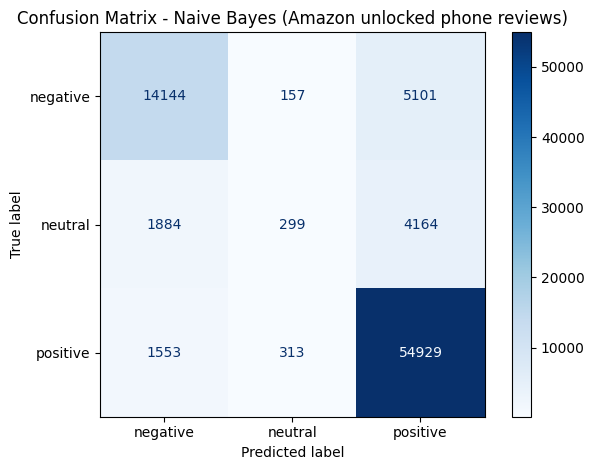

In [21]:
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Naive Bayes (Amazon unlocked phone reviews)')
plt.tight_layout()
plt.show()

In [22]:
recall_per_class = cm.diagonal() / cm.sum(axis=1)

print('========== Results ==========')
print('Number of training reviews:', X_train_tfidf.shape[0])
print('Number of testing reviews :', X_test_tfidf.shape[0])
print(f'Accuracy on the test set  : {nb_accuracy:.4f}')
print('Correctly classified reviews of each class:')
for label, correct, total, recall in zip(labels, cm.diagonal(), cm.sum(axis=1), recall_per_class):
    print(f'  {label:<9} {correct:>6} / {total:<6} ({recall:.1%})')

========== Results ==========
Number of training reviews: 330175
Number of testing reviews : 82544
Accuracy on the test set  : 0.8404
Correctly classified reviews of each class:
  negative   14144 / 19402  (72.9%)
  neutral      299 / 6347   (4.7%)
  positive   54929 / 56795  (96.7%)


_____________________________________________________________________________________________

# What I Learned from Lab 4

In this lab I learned how to build a complete **text classification** model for sentiment analysis and, more importantly, how to **evaluate** it correctly.

### The Text Classification Pipeline
- Text classification gives a predefined label to a text. Examples are spam detection, news categorization and sentiment analysis.
- The steps are always the same: load the data → pre-process the text → split into train and test → extract features → train a classifier → evaluate.
- Star ratings can be turned into sentiment labels: 4–5 stars → `positive`, 3 stars → `neutral`, 1–2 stars → `negative`.
- In the Disneyland example a linear **SVM** with TF-IDF features got an accuracy of **0.84** on 42,656 reviews.

### Task 1: Loading and Pre-processing the Amazon Reviews
- I loaded **413,840 reviews** of unlocked phones and dropped the 70 rows that had no review text.
- I applied 5 pre-processing steps: lower casing, removing URLs/numbers/punctuation with regular expressions, tokenization, stop words removal and lemmatization.
- I **kept the words `no`, `not` and `nor`** when removing stop words, because "not good" means the opposite of "good" in sentiment analysis.
- After cleaning, some reviews became empty (only emojis or numbers), so I removed them. **412,719 reviews** were left.
- The classes are **not balanced**: 68.8% positive, 23.5% negative and only 7.7% neutral.

### Tasks 2 – 4: Split, TF-IDF and Naive Bayes
- I split the data into 80% training (**330,175**) and 20% testing (**82,544**). I used `stratify` so both sets keep the same class percentages.
- The TF-IDF vectorizer must be **fitted on the training set only** (`fit_transform`) and then only applied to the test set (`transform`). Otherwise information from the test set leaks into training.
- `MultinomialNB` is a good first classifier for text. It trained on 330,175 reviews in about a second, while the SVM in the example needed many minutes for only 34,124 reviews.

### Tasks 5 – 6: Evaluation and the Confusion Matrix
- The accuracy on the test set was **0.84**, but accuracy alone hides an important problem.
- The classification report showed very different results for each class:
  - `positive`: precision 0.86, recall **0.97**
  - `negative`: precision 0.80, recall **0.73**
  - `neutral`: precision 0.39, recall **0.05**
- The confusion matrix showed where the mistakes are: only **299 of 6,347** neutral reviews were classified correctly. 4,164 of them were predicted as positive and 1,884 as negative.
- I learned the meaning of the metrics: **precision** is how many of the predicted reviews of a class are really from that class, **recall** is how many of the real reviews of a class the model found, and **F1-score** combines the two.
- The **macro average** F1 (0.59) treats every class equally, so it shows the weak neutral class. The **weighted average** (0.81) is dominated by the large positive class.

### Why the Neutral Class Is Hard
- It is the smallest class, and Naive Bayes prefers the classes with more examples.
- 3-star reviews usually mix positive and negative words ("good phone but the battery is bad"), so they look like both other classes.
- When I tried the model on my own sentence "The phone is okay, nothing special but it works.", it predicted `positive`.
- The same thing happened with the SVM on the Disneyland reviews (neutral recall 0.18), so this is a problem of the data and not of one model.

**Conclusion:** A model should never be judged by accuracy alone, especially when the classes are not balanced. The classification report and the confusion matrix show which classes the model really learned and where it makes its mistakes.